In [ ]:
import pandas as pd

gen_df = pd.read_csv('Plant_1_Generation_Data.csv')
weather_df = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

print("=== GENERATION DATA SHAPE ===")
print(f"Rows: {gen_df.shape[0]}, Columns: {gen_df.shape[1]}")

print("\n=== WEATHER DATA SHAPE ===")
print(f"Rows: {weather_df.shape[0]}, Columns: {weather_df.shape[1]}")

print("\n=== GENERATION DATA COLUMNS & TYPES ===")
print(gen_df.dtypes)

print("\n=== WEATHER DATA COLUMNS & TYPES ===")
print(weather_df.dtypes)

print("\n=== FIRST 3 ROWS: GENERATION DATA ===")
display(gen_df.head(3))

print("\n=== FIRST 3 ROWS: WEATHER DATA ===")
display(weather_df.head(3))

=== GENERATION DATA SHAPE ===
Rows: 68778, Columns: 7

=== WEATHER DATA SHAPE ===
Rows: 3182, Columns: 6

=== GENERATION DATA COLUMNS & TYPES ===
DATE_TIME       object
PLANT_ID         int64
SOURCE_KEY      object
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

=== WEATHER DATA COLUMNS & TYPES ===
DATE_TIME               object
PLANT_ID                 int64
SOURCE_KEY              object
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object

=== FIRST 3 ROWS: GENERATION DATA ===


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0



=== FIRST 3 ROWS: WEATHER DATA ===


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0


Datetime conversion successful!
Generation date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Weather date range:    2020-05-15 00:00:00 to 2020-06-17 23:45:00

Merged dataset shape: 68774 rows, 10 columns

Missing values per column:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Duplicate records (same inverter at same timestamp): 0

Summary statistics of key numerical columns:


,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,DC_POWER,AC_POWER,HOUR
count,68774.00,68774.00,68774.00,68774.00,68774.00,68774.00
mean,0.23,25.56,31.24,3147.18,307.78,11.57
std,0.30,3.36,12.31,4036.44,394.39,6.86
min,0.00,20.40,18.14,0.00,0.00,0.00
25%,0.00,22.72,21.12,0.00,0.00,6.00
50%,0.03,24.67,24.82,428.57,41.45,12.00
75%,0.45,27.96,41.69,6365.47,623.56,17.00
max,1.22,35.25,65.55,14471.12,1410.95,23.00


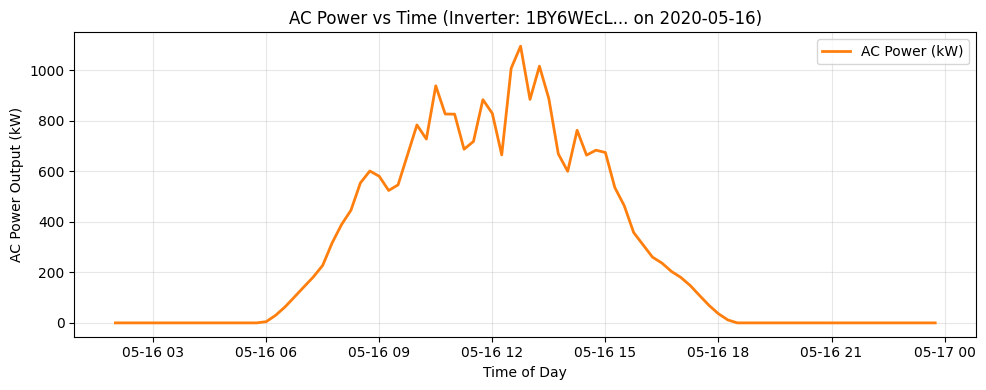


Correlation of features with AC_POWER:
IRRADIATION            0.989
MODULE_TEMPERATURE     0.955
AMBIENT_TEMPERATURE    0.725
HOUR                   0.024
AC_POWER               1.000
Name: AC_POWER, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


gen_df['DATE_TIME'] = pd.to_datetime(gen_df['DATE_TIME'], dayfirst=True)
weather_df['DATE_TIME'] = pd.to_datetime(weather_df['DATE_TIME'])

print("Datetime conversion successful!")
print(f"Generation date range: {gen_df['DATE_TIME'].min()} to {gen_df['DATE_TIME'].max()}")
print(f"Weather date range:    {weather_df['DATE_TIME'].min()} to {weather_df['DATE_TIME'].max()}")


weather_clean = weather_df.drop(columns=['PLANT_ID', 'SOURCE_KEY'])


merged_df = pd.merge(gen_df, weather_clean, on='DATE_TIME', how='inner')

print(f"\nMerged dataset shape: {merged_df.shape[0]} rows, {merged_df.shape[1]} columns")


print("\nMissing values per column:")
print(merged_df.isnull().sum())

duplicate_count = merged_df.duplicated(subset=['DATE_TIME', 'SOURCE_KEY']).sum()
print(f"\nDuplicate records (same inverter at same timestamp): {duplicate_count}")


merged_df['HOUR'] = merged_df['DATE_TIME'].dt.hour
merged_df['DAY'] = merged_df['DATE_TIME'].dt.day
merged_df['DAY_OF_WEEK'] = merged_df['DATE_TIME'].dt.dayofweek


key_columns = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'DC_POWER', 'AC_POWER', 'HOUR']
print("\nSummary statistics of key numerical columns:")
display(merged_df[key_columns].describe().round(2))


sample_inverter = merged_df['SOURCE_KEY'].unique()[0]
sample_day = merged_df[(merged_df['SOURCE_KEY'] == sample_inverter) &
                       (merged_df['DATE_TIME'].dt.date == merged_df['DATE_TIME'].dt.date.unique()[1])]

plt.figure(figsize=(10, 4))
plt.plot(sample_day['DATE_TIME'], sample_day['AC_POWER'], color='tab:orange', label='AC Power (kW)', linewidth=2)
plt.title(f"AC Power vs Time (Inverter: {sample_inverter[:8]}... on {sample_day['DATE_TIME'].dt.date.iloc[0]})")
plt.xlabel("Time of Day")
plt.ylabel("AC Power Output (kW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

correlation = merged_df[['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'HOUR', 'AC_POWER']].corr()['AC_POWER']
print("\nCorrelation of features with AC_POWER:")
print(correlation.round(3))

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

feature_cols = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR']
target_col = 'AC_POWER'

df_sorted = merged_df.sort_values(by='DATE_TIME').reset_index(drop=True)
split_index = int(len(df_sorted) * 0.80)

train_df = df_sorted.iloc[:split_index]
test_df = df_sorted.iloc[split_index:]

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"Training records: {len(X_train)} (from {train_df['DATE_TIME'].min().date()} to {train_df['DATE_TIME'].max().date()})")
print(f"Testing records:  {len(X_test)} (from {test_df['DATE_TIME'].min().date()} to {test_df['DATE_TIME'].max().date()})")

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)


y_pred_lr = lr_model.predict(X_test)

y_pred_lr = np.clip(y_pred_lr, a_min=0, a_max=None)


mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\n=== LINEAR REGRESSION EVALUATION ===")
print(f"MAE  (Mean Absolute Error):     {mae_lr:.2f} kW")
print(f"RMSE (Root Mean Squared Error): {rmse_lr:.2f} kW")
print(f"R² Score:                       {r2_lr:.4f}")


print("\nLearned Weights (Coefficients):")
for feat, coef in zip(feature_cols, lr_model.coef_):
    print(f"  {feat:20s}: {coef:+.4f}")
print(f"  Intercept (bias):    {lr_model.intercept_:+.4f}")

Training records: 55019 (from 2020-05-15 to 2020-06-11)
Testing records:  13755 (from 2020-06-11 to 2020-06-17)

=== LINEAR REGRESSION EVALUATION ===
MAE  (Mean Absolute Error):     27.52 kW
RMSE (Root Mean Squared Error): 58.83 kW
R² Score:                       0.9742

Learned Weights (Coefficients):
  IRRADIATION         : +1199.9718
  AMBIENT_TEMPERATURE : -0.2520
  MODULE_TEMPERATURE  : +2.1477
  HOUR                : -0.1381
  Intercept (bias):    -32.6097


In [4]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_model = DecisionTreeRegressor(max_depth=6, random_state=42)

dt_model.fit(X_train, y_train)


y_pred_dt = dt_model.predict(X_test)
y_pred_dt = np.clip(y_pred_dt, a_min=0, a_max=None)


mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("=== DECISION TREE EVALUATION ===")
print(f"MAE  (Mean Absolute Error):     {mae_dt:.2f} kW")
print(f"RMSE (Root Mean Squared Error): {rmse_dt:.2f} kW")
print(f"R² Score:                       {r2_dt:.4f}")

print("\n=== HEAD-TO-HEAD COMPARISON SO FAR ===")
print(f"{'Model':<20} | {'MAE (kW)':<10} | {'RMSE (kW)':<10} | {'R² Score':<10}")
print("-" * 55)
print(f"{'Linear Regression':<20} | {mae_lr:<10.2f} | {rmse_lr:<10.2f} | {r2_lr:<10.4f}")
print(f"{'Decision Tree':<20} | {mae_dt:<10.2f} | {rmse_dt:<10.2f} | {r2_dt:<10.4f}")

print("\nFeature Importances (How much the tree relied on each feature):")
for feat, imp in zip(feature_cols, dt_model.feature_importances_):
    print(f"  {feat:20s}: {imp * 100:.2f}%")

=== DECISION TREE EVALUATION ===
MAE  (Mean Absolute Error):     18.84 kW
RMSE (Root Mean Squared Error): 53.51 kW
R² Score:                       0.9786

=== HEAD-TO-HEAD COMPARISON SO FAR ===
Model                | MAE (kW)   | RMSE (kW)  | R² Score  
-------------------------------------------------------
Linear Regression    | 27.52      | 58.83      | 0.9742    
Decision Tree        | 18.84      | 53.51      | 0.9786    

Feature Importances (How much the tree relied on each feature):
  IRRADIATION         : 99.91%
  AMBIENT_TEMPERATURE : 0.03%
  MODULE_TEMPERATURE  : 0.03%
  HOUR                : 0.02%


In [5]:
# -------------------------------------------------------------
# Stage 5: Algorithm 3 - K-Nearest Neighbors (KNN) Regressor
# -------------------------------------------------------------

from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Feature Scaling (Mandatory for distance-based models)
# Fit the scaler ONLY on X_train to prevent future test information from leaking into training
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully!")
print(f"X_train scaled mean per feature (should be ~0): {X_train_scaled.mean(axis=0).round(2)}")
print(f"X_train scaled std per feature (should be ~1):  {X_train_scaled.std(axis=0).round(2)}")

# 2. Initialize KNN Regressor
# - n_neighbors=7: averages the 7 most similar historical weather readings
# - weights='distance': points closer in weather have a stronger vote
knn_model = KNeighborsRegressor(n_neighbors=7, weights='distance')

# 3. Fit on the SCALED training data
knn_model.fit(X_train_scaled, y_train)

# 4. Predict on the SCALED test data
y_pred_knn = knn_model.predict(X_test_scaled)
y_pred_knn = np.clip(y_pred_knn, a_min=0, a_max=None)

# 5. Evaluate Performance
mae_knn = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))
r2_knn = r2_score(y_test, y_pred_knn)

print("\n=== KNN REGRESSOR EVALUATION ===")
print(f"MAE  (Mean Absolute Error):     {mae_knn:.2f} kW")
print(f"RMSE (Root Mean Squared Error): {rmse_knn:.2f} kW")
print(f"R² Score:                       {r2_knn:.4f}")

# 6. Side-by-Side 3-Model Comparison Table
print("\n" + "="*62)
print(f"{'REGRESSION ALGORITHM':<24} | {'MAE (kW)':<10} | {'RMSE (kW)':<10} | {'R² SCORE':<10}")
print("="*62)
print(f"{'1. Linear Regression':<24} | {mae_lr:<10.2f} | {rmse_lr:<10.2f} | {r2_lr:<10.4f}")
print(f"{'2. Decision Tree':<24} | {mae_dt:<10.2f} | {rmse_dt:<10.2f} | {r2_dt:<10.4f}")
print(f"{'3. KNN Regressor':<24} | {mae_knn:<10.2f} | {rmse_knn:<10.2f} | {r2_knn:<10.4f}")
print("="*62)

Features scaled successfully!
X_train scaled mean per feature (should be ~0): [-0.  0.  0.  0.]
X_train scaled std per feature (should be ~1):  [1. 1. 1. 1.]

=== KNN REGRESSOR EVALUATION ===
MAE  (Mean Absolute Error):     24.03 kW
RMSE (Root Mean Squared Error): 59.08 kW
R² Score:                       0.9739

REGRESSION ALGORITHM     | MAE (kW)   | RMSE (kW)  | R² SCORE  
1. Linear Regression     | 27.52      | 58.83      | 0.9742    
2. Decision Tree         | 18.84      | 53.51      | 0.9786    
3. KNN Regressor         | 24.03      | 59.08      | 0.9739    


In [6]:
# -------------------------------------------------------------
# Stage 6: Label Creation & Algorithm 4 - Logistic Regression
# -------------------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import numpy as np
import pandas as pd

# --- STEP 6.1: CREATE THE GROUND-TRUTH LABELS ---
# We use our Decision Tree (trained only on the training set!) to calculate baseline expected power
# This prevents data leakage: test expected power is evaluated by a model trained strictly on past data.
df_sorted['EXPECTED_POWER'] = dt_model.predict(df_sorted[feature_cols])

# Rule: Underperforming if daylight (IRRADIATION > 0.05) AND actual power is < 80% of expected power
UNDERPERFORMANCE_THRESHOLD = 0.80
DAYLIGHT_MIN_IRRADIATION = 0.05

is_daylight = df_sorted['IRRADIATION'] > DAYLIGHT_MIN_IRRADIATION
has_shortfall = df_sorted['AC_POWER'] < (UNDERPERFORMANCE_THRESHOLD * df_sorted['EXPECTED_POWER'])

df_sorted['LABEL'] = np.where(is_daylight & has_shortfall, 1, 0)

print("=== DATASET CLASS DISTRIBUTION ===")
total_records = len(df_sorted)
normal_count = (df_sorted['LABEL'] == 0).sum()
underperforming_count = (df_sorted['LABEL'] == 1).sum()

print(f"Total Records:         {total_records}")
print(f"Normal (0):            {normal_count} ({normal_count / total_records * 100:.1f}%)")
print(f"Underperforming (1):   {underperforming_count} ({underperforming_count / total_records * 100:.1f}%)")


# --- STEP 6.2: CHRONOLOGICAL TRAIN/TEST SPLIT FOR CLASSIFICATION ---
train_clf = df_sorted.iloc[:split_index]
test_clf = df_sorted.iloc[split_index:]

# Features given to the classifier: weather + time + actual power output
clf_features = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR', 'AC_POWER']

X_train_clf = train_clf[clf_features]
y_train_clf = train_clf['LABEL']

X_test_clf = test_clf[clf_features]
y_test_clf = test_clf['LABEL']


# --- STEP 6.3: SCALE FEATURES ---
# Logistic Regression relies on gradient descent; feature scaling ensures fast, stable convergence
scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)


# --- STEP 6.4: TRAIN LOGISTIC REGRESSION ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_clf_scaled, y_train_clf)

# --- STEP 6.5: PREDICT AND EVALUATE ON UNSEEN TEST DATA ---
y_pred_clf = log_reg.predict(X_test_clf_scaled)

accuracy = accuracy_score(y_test_clf, y_pred_clf)
precision = precision_score(y_test_clf, y_pred_clf, zero_division=0)
recall = recall_score(y_test_clf, y_pred_clf, zero_division=0)
f1 = f1_score(y_test_clf, y_pred_clf, zero_division=0)
cm = confusion_matrix(y_test_clf, y_pred_clf)

print("\n=== LOGISTIC REGRESSION EVALUATION METRICS ===")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%  (When alert sounds, how often is it true?)")
print(f"Recall:    {recall * 100:.2f}%  (What % of real underperformance was caught?)")
print(f"F1-Score:  {f1 * 100:.2f}%  (Harmonic mean of Precision and Recall)")

print("\n=== CONFUSION MATRIX ===")
print(f"                  Predicted Normal (0) | Predicted Underperforming (1)")
print(f"Actual Normal (0):        {cm[0][0]:<12} | {cm[0][1]:<12} (False Alarms)")
print(f"Actual Underperf (1):     {cm[1][0]:<12} | {cm[1][1]:<12} (Correct Alerts)")

=== DATASET CLASS DISTRIBUTION ===
Total Records:         68774
Normal (0):            68200 (99.2%)
Underperforming (1):   574 (0.8%)

=== LOGISTIC REGRESSION EVALUATION METRICS ===
Accuracy:  99.85%
Precision: 100.00%  (When alert sounds, how often is it true?)
Recall:    59.62%  (What % of real underperformance was caught?)
F1-Score:  74.70%  (Harmonic mean of Precision and Recall)

=== CONFUSION MATRIX ===
                  Predicted Normal (0) | Predicted Underperforming (1)
Actual Normal (0):        13703        | 0            (False Alarms)
Actual Underperf (1):     21           | 31           (Correct Alerts)


In [7]:
# -------------------------------------------------------------
# Stage 7: Model Comparison & Underperformance Detector Engine
# -------------------------------------------------------------

import pandas as pd
import numpy as np

# --- STEP 7.1: MASTER EVALUATION SUMMARY ---
print("=" * 70)
print("             SOLAR ML PROJECT: MASTER EVALUATION TABLE")
print("=" * 70)

reg_summary = pd.DataFrame({
    'Algorithm': ['Linear Regression', 'Decision Tree Regressor', 'KNN Regressor'],
    'Type': ['Regression (Baseline)', 'Regression (Non-linear)', 'Regression (Instance-based)'],
    'MAE (kW)': [mae_lr, mae_dt, mae_knn],
    'RMSE (kW)': [rmse_lr, rmse_dt, rmse_knn],
    'R² Score': [r2_lr, r2_dt, r2_knn]
})
display(reg_summary.round(3))

print("\n--- CLASSIFICATION ALGORITHM ---")
clf_summary = pd.DataFrame({
    'Algorithm': ['Logistic Regression'],
    'Type': ['Binary Classification'],
    'Accuracy': [f"{accuracy * 100:.2f}%"],
    'Precision': [f"{precision * 100:.2f}%"],
    'Recall': [f"{recall * 100:.2f}%"],
    'F1-Score': [f"{f1 * 100:.2f}%"]
})
display(clf_summary)


# --- STEP 7.2: THE UNDERPERFORMANCE DETECTION FUNCTION ---
def evaluate_solar_performance(irradiation, ambient_temp, module_temp, hour,
                               actual_power=None, shortfall_threshold_pct=20.0):
    """
    Transparent detector that:
    1. Estimates expected power from weather.
    2. Compares with actual output if provided.
    3. Prevents nighttime false alerts.
    4. Computes percentage shortfall against a configurable threshold.
    5. Gets Logistic Regression classification probability.
    """
    # 1. Physical input check: Is it dark / night?
    if irradiation <= 0.05:
        return {
            "status": "Normal (Night/Low Sun)",
            "expected_power_kw": 0.0,
            "actual_power_kw": 0.0 if actual_power is None else actual_power,
            "shortfall_kw": 0.0,
            "shortfall_pct": 0.0,
            "flagged": False,
            "clf_prediction": "Normal",
            "message": "Solar irradiance is near zero (night or dawn/dusk). No power generation expected."
        }

    # 2. Estimate Expected Power using Decision Tree Regressor
    input_features = pd.DataFrame([[irradiation, ambient_temp, module_temp, hour]],
                                  columns=['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR'])
    expected_power = float(dt_model.predict(input_features)[0])
    expected_power = max(0.0, expected_power)

    result = {
        "expected_power_kw": round(expected_power, 2),
        "actual_power_kw": actual_power,
        "shortfall_kw": None,
        "shortfall_pct": None,
        "flagged": False,
        "clf_prediction": "N/A",
        "clf_probability_underperf": "N/A",
        "status": "Expected Output Calculated",
        "message": "Only weather measurements provided. Actual power required for underperformance detection."
    }

    # 3. If actual power was supplied, run comparison and classification
    if actual_power is not None:
        shortfall_kw = expected_power - actual_power
        shortfall_pct = (shortfall_kw / expected_power) * 100.0 if expected_power > 0 else 0.0

        result["shortfall_kw"] = round(shortfall_kw, 2)
        result["shortfall_pct"] = round(shortfall_pct, 2)

        # Rule-based threshold check
        is_underperforming_by_rule = shortfall_pct >= shortfall_threshold_pct
        result["flagged"] = is_underperforming_by_rule

        # Logistic Regression classification check
        clf_input = pd.DataFrame([[irradiation, ambient_temp, module_temp, hour, actual_power]],
                                 columns=['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR', 'AC_POWER'])
        clf_input_scaled = scaler_clf.transform(clf_input)
        clf_pred = log_reg.predict(clf_input_scaled)[0]
        clf_prob = log_reg.predict_proba(clf_input_scaled)[0][1] # Probability of class 1 (Underperforming)

        result["clf_prediction"] = "Underperforming" if clf_pred == 1 else "Normal"
        result["clf_probability_underperf"] = f"{clf_prob * 100:.1f}%"

        if is_underperforming_by_rule or clf_pred == 1:
            result["status"] = "⚠️ Possible Underperformance Detected"
            result["message"] = (f"Actual generation is {shortfall_pct:.1f}% below expected output "
                                 f"(Threshold: {shortfall_threshold_pct}%). "
                                 f"Note: This flags operational underperformance, not a confirmed hardware fault.")
        else:
            result["status"] = "✅ Normal Operation"
            result["message"] = "Actual power output is within healthy operational range for current weather conditions."

    return result


# --- STEP 7.3: TEST THE ENGINE ON 3 REAL-WORLD SCENARIOS ---
print("\n" + "=" * 70)
print("             TESTING THE ENGINE ON 3 SCENARIOS")
print("=" * 70)

# Scenario A: Sunny noon, inverter producing healthy ~780 kW
print("\n--- SCENARIO A: HEALTHY MIDDAY OPERATION ---")
res_a = evaluate_solar_performance(irradiation=0.82, ambient_temp=33.0, module_temp=52.0, hour=12, actual_power=780.0)
for k, v in res_a.items():
    print(f"  {k:26s}: {v}")

# Scenario B: Sunny noon, but inverter producing only 350 kW (severe drop!)
print("\n--- SCENARIO B: ABNORMAL OUTPUT (UNDERPERFORMANCE) ---")
res_b = evaluate_solar_performance(irradiation=0.82, ambient_temp=33.0, module_temp=52.0, hour=12, actual_power=350.0)
for k, v in res_b.items():
    print(f"  {k:26s}: {v}")

# Scenario C: Nighttime (2:00 AM)
print("\n--- SCENARIO C: NIGHTTIME SAFETY CHECK ---")
res_c = evaluate_solar_performance(irradiation=0.0, ambient_temp=22.0, module_temp=20.0, hour=2, actual_power=0.0)
for k, v in res_c.items():
    print(f"  {k:26s}: {v}")

             SOLAR ML PROJECT: MASTER EVALUATION TABLE


,Algorithm,Type,MAE (kW),RMSE (kW),R² Score
0,Linear Regression,Regression (Baseline),27.523,58.831,0.974
1,Decision Tree Regressor,Regression (Non-linear),18.841,53.506,0.979
2,KNN Regressor,Regression (Instance-based),24.034,59.079,0.974



--- CLASSIFICATION ALGORITHM ---


,Algorithm,Type,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,Binary Classification,99.85%,100.00%,59.62%,74.70%



             TESTING THE ENGINE ON 3 SCENARIOS

--- SCENARIO A: HEALTHY MIDDAY OPERATION ---
  expected_power_kw         : 1030.12
  actual_power_kw           : 780.0
  shortfall_kw              : 250.12
  shortfall_pct             : 24.28
  flagged                   : True
  clf_prediction            : Underperforming
  clf_probability_underperf : 69.0%
  status                    : ⚠️ Possible Underperformance Detected
  message                   : Actual generation is 24.3% below expected output (Threshold: 20.0%). Note: This flags operational underperformance, not a confirmed hardware fault.

--- SCENARIO B: ABNORMAL OUTPUT (UNDERPERFORMANCE) ---
  expected_power_kw         : 1030.12
  actual_power_kw           : 350.0
  shortfall_kw              : 680.12
  shortfall_pct             : 66.02
  flagged                   : True
  clf_prediction            : Underperforming
  clf_probability_underperf : 100.0%
  status                    : ⚠️ Possible Underperformance Detected
  messa

In [8]:
# -------------------------------------------------------------
# Stage 8: Save Models, Scalers, and Sample Data with joblib
# -------------------------------------------------------------

import joblib
import os
import shutil

# 1. Create a directory named 'models'
os.makedirs('models', exist_ok=True)

# 2. Save all four trained models
joblib.dump(lr_model, 'models/linear_regression_model.joblib')
joblib.dump(dt_model, 'models/decision_tree_model.joblib')
joblib.dump(knn_model, 'models/knn_model.joblib')
joblib.dump(log_reg, 'models/logistic_regression_model.joblib')

# 3. Save the scalers (Crucial for consistent inference)
joblib.dump(scaler, 'models/scaler_knn.joblib')
joblib.dump(scaler_clf, 'models/scaler_classifier.joblib')

# 4. Save evaluation metrics for the Streamlit dashboard
metrics_summary = {
    'regression': [
        {'model': 'Linear Regression', 'mae': round(mae_lr, 2), 'rmse': round(rmse_lr, 2), 'r2': round(r2_lr, 4)},
        {'model': 'Decision Tree Regressor', 'mae': round(mae_dt, 2), 'rmse': round(rmse_dt, 2), 'r2': round(r2_dt, 4)},
        {'model': 'KNN Regressor', 'mae': round(mae_knn, 2), 'rmse': round(rmse_knn, 2), 'r2': round(r2_knn, 4)}
    ],
    'classification': {
        'model': 'Logistic Regression',
        'accuracy': round(accuracy * 100, 2),
        'precision': round(precision * 100, 2),
        'recall': round(recall * 100, 2),
        'f1': round(f1 * 100, 2)
    }
}
joblib.dump(metrics_summary, 'models/metrics_summary.joblib')

# 5. Export a 100-row sample CSV from the test set for testing file uploads
sample_csv = test_df[['DATE_TIME', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'AC_POWER']].head(100)
sample_csv.to_csv('sample_solar_data.csv', index=False)

print("Saved files in 'models/':")
for file in os.listdir('models'):
    print(f"  ✓ models/{file}")
print("  ✓ sample_solar_data.csv")

# 6. Compress the models folder into a single zip file for easy download
shutil.make_archive('models_bundle', 'zip', 'models')

# 7. Trigger download to your local computer
from google.colab import files
files.download('models_bundle.zip')
files.download('sample_solar_data.csv')

Saved files in 'models/':
  ✓ models/logistic_regression_model.joblib
  ✓ models/decision_tree_model.joblib
  ✓ models/knn_model.joblib
  ✓ models/scaler_classifier.joblib
  ✓ models/linear_regression_model.joblib
  ✓ models/metrics_summary.joblib
  ✓ models/scaler_knn.joblib
  ✓ sample_solar_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>